# GCALS: Gradient Controlled Adaptive Label Smoothing

## Introduction
Label smoothing is a widely adopted regularization technique in deep learning. It modifies target distribution from one-hot encoding to a uniformly distributed probability mass. This method restricts model from making overly confident predictions. It adds uncertainty to model's prediction.
<br>

Generally, we choose a label smoothing parameter remains static/ constant throughout the training process. Although this will prevent model from making overly confident prediction, it can also prevent model to learn sharper patterns in early stages of training.
<br>

GCALS is a label smoothing parameter adapter that depends upon relative confidence of the model derived from the decomposed gradient's $L2$ norm.
<br>
<br>

---

## Derivation

### Decomposing Loss

#### Loss Function Decomposition:




<br>

We start from defination of CCE loss with lable smoothing,

$$CCE_{LS}= - \sum_{i=1}^K P_i * log(\sigma_i)$$

Where,<br>
$K = Total \space number \space of \space class$<br>
$P = Smoothed \space targets$<br>
$\sigma = Softmax \space probabilities$<br><br>

Expanding the sum,
$$CCE_{LS}= - (1-\epsilon + \frac{\epsilon}{K}) * log(\sigma_t) - \sum_{j \neq t} P_j * log(\sigma_j)$$
<br><br>
Where $t$ represents index of correct class. This can be written as,

$$CCE_{LS}= L* (1-\epsilon + \frac{\epsilon}{K}) - \frac{\epsilon}{K} \sum_{i=1}^{K} (1-Y_i) *log(\sigma_i)$$
<br><br>
Where $L$ and $Y$ represent CCE Loss without label smoothing and one-hot targets respectively.
$$
CCE_{LS} = (1-\epsilon + \frac{\epsilon}{K})L + \text{Reg}(\sigma, Y)
$$
<br><br>
where, $\text{Reg}(\sigma, Y) = -\frac{\epsilon}{K}\sum_{i=1}^K (1-Y_i)\log(\sigma_i)$.
<br><br>

---
<br><br>


#### Finding Gradient: <br><br>



Differentiating $CCE_{LS}$ with respect to the logits $z$ using the chain rule:<br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z} + \frac{\partial \text{Reg}}{\partial \sigma}\frac{\partial \sigma}{\partial z}
$$ <br><br>

Evaluating the derivative of the penalty term with respect to $\sigma$ elementwise gives:<br><br>
$$
\frac{\partial \text{Reg}}{\partial \sigma} = -\frac{\epsilon}{K}\frac{1-Y}{\sigma}
$$<br><br>

Combining this vector with the softmax Jacobian $\frac{\partial \sigma}{\partial z} = \text{diag}(\sigma) - \sigma\sigma^T$ and carrying out the matrix multiplication yields the final decomposed gradient:<br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z} - \frac{\epsilon}{K}(1-Y) + \frac{K-1}{K}\epsilon\sigma
$$<br><br>

Here first term is the scaled gradient of CCE without label smoothing and two other terms are seen to be implicitly added due to label smoothing. Let's write it as, <br><br>
$$
\frac{\partial CCE_{LS}}{\partial z} = G_1 + G_2
$$<br><br>

Where,<br><br>
$G_1 = (1-\epsilon + \frac{\epsilon}{K})\frac{\partial L}{\partial z}$<br><br>
$G_2 = \frac{K-1}{K}\epsilon\sigma - \frac{\epsilon}{K}(1-Y)$
<br><br>

---

<br><br>



### Formulating GCALS


#### Overview

During training process we can expect loss to start very large because the model hasn't learned any meaningful pattern information yet. Therefore, the magnitude of $G_1$ can be expected to be relatively larger. In contrast, in the later stages of training, the magnitude of $G_1$ is relatively smaller. While this is the optimization goal, this can also lead to overfitting. So, to prevent overfitting, label smoothing can be used. Adding label smoothing is seen to introduce new term $G_2$ in the decomposed gradient. Magnitude of $G_2$ depends upon softmax probabilities (i.e. confidence of model for each class). As the model make strongly confident predictions, the magnitude of $G_2$ becomes larger is added to total gradients, which during optimization process penalizes the weights. But, static label smoothing can restrict the model from learning complex meaningful patterns in earlier stage of training, this can make loss convergence quite slower. To prevent this GCALS (Gradient Controlled Adaptive Label Smoothing) is formulated.

#### Derivation


<br><br>
Let's define a ratio $\gamma$ that measures the relative confidence of the model with respect to $L2$ norm of $G_1$ and $G_2$.
$$\gamma = \frac{\lVert G_2 \rVert_2}{\lVert G_1 \rVert_2 + \alpha}$$

<br><br> Where $\alpha$ is infinitesimal value to prevent zero division error.
<br><br>
$\gamma$ explodes to $\infty$ as $\lVert G_1 \rVert_2$ reaches 0. Which shows the model is highly or overly confident about it's prediction. Now, we can smoothly increase label smoothing parameter $\epsilon$ as the model gains higher confidence ($\gamma$ becomes larger) using exponential saturation function. <br><br>
$$\epsilon = \epsilon_{max} ⋅ (1 - e^{-\gamma})$$
<br><br> $\epsilon_{max}$ is the maximum value the label smoothing parameter that user can estimate reasonably.
<br><br>
Additionally, we can also use exponential moving average on calculated $\epsilon$ to ensure $\epsilon$ updates in smoothly with stability.<br><br>
$$\epsilon_{t} = (1 - \beta)\cdot \epsilon + \beta \cdot \epsilon_{t-1}$$
<br><br>Where $\beta$ is the decay factor.<br><br>

---
<br><br>

Note: <br>
In the code, I have set a minimum value for $\epsilon$ because in early stage, it would be extremely small that the following updates on it would be negligible. To prevent this I set a minimum cap for the label smoothing parameter $\epsilon$.

## Experiment

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import ssl


In [4]:
class GCALS(nn.Module):
    def __init__(self, eps_max=None, num_classes=10):
        super().__init__()
        self.min_epsilon = 0.0001
        self.epsilon = self.min_epsilon
        self.eps_max = eps_max
        # self.curr_eps_max= self.eps_max
        self.num_classes = num_classes
        self.gamma = 0.0
        self.beta = 0.95

    def update_epsilon(self, logits, targets):
          with torch.no_grad():

              # if self.eps_max * 62 / 100 <= self.epsilon and self.curr_eps_max <= self.eps_max * 1.62:
              #   self.curr_eps_max += abs(self.eps_max*(self.curr_eps_max - self.eps_max))

              softmaxes = F.softmax(logits, dim=-1)
              y_one_hot = F.one_hot(targets, num_classes=self.num_classes).float()

              G_1 = (1.0 - self.epsilon + self.epsilon / self.num_classes) * (softmaxes - y_one_hot)

              numerator = 1.0 - y_one_hot
              G_2 = (self.epsilon) * softmaxes * ((self.num_classes - 1) / self.num_classes) - (self.epsilon / (self.num_classes)) * numerator

              f_grad_norm = torch.norm(G_1, p=2, dim=-1).mean().item()
              f_reg_norm = torch.norm(G_2, p=2, dim=-1).mean().item()
              

              self.gamma = f_reg_norm / (f_grad_norm + 1e-8)

              target_epsilon = max(self.min_epsilon, self.eps_max * (1.0 - np.exp(-self.gamma)))

              self.epsilon = (1.0 - self.beta) * target_epsilon + self.beta * self.epsilon



    def forward(self, logits, targets):
        self.update_epsilon(logits, targets)
        loss = F.cross_entropy(logits, targets, label_smoothing=self.epsilon)
        return loss


In [5]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

ssl._create_default_https_context = ssl._create_unverified_context

torchvision.datasets.CIFAR10.url = "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"

train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
full_loader = torch.utils.data.DataLoader(train_dataset, batch_size=len(train_dataset), shuffle=False)

all_images, all_labels = next(iter(full_loader))
# all_images, all_labels = all_images.to(device), all_labels.to(device)


In [7]:
train_image, train_label = all_images[:30000], all_labels[:30000]
test_image, test_label = all_images[30000:], all_labels[30000:]

train = torch.utils.data.TensorDataset(train_image, train_label)
test = torch.utils.data.TensorDataset(test_image, test_label)


train_loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True, drop_last=True)
test_loader = torch.utils.data.DataLoader(test, batch_size=128, shuffle=False)

In [8]:
num_epochs = 35
num_classes = 10


def train_track(mode="gcals", eps=None):
  torch.manual_seed(42)

  model = torchvision.models.resnet18(num_classes=num_classes)
  model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
  model.maxpool = nn.Identity()

  if torch.cuda.device_count() > 1:
    print(f"Using {torch.cuda.device_count()} GPUs for training!")
    model = nn.DataParallel(model)
    
  model = model.to(device)

  optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)


  if mode == "gcals":
    criterion = GCALS(eps_max=eps, num_classes=num_classes)
  elif mode == "static":
    criterion = lambda lg, tg: F.cross_entropy(lg, tg, label_smoothing=eps)
  else:
    criterion = lambda lg, tg: F.cross_entropy(lg, tg, label_smoothing=0.0)

  train_loss_log = []
  test_loss_log = []
  test_acc_log = []
  eps_log = []

  print(f"\n--- Launching {mode.upper()} Track ---")
  for epoch in range(num_epochs):

    model.train()
    running_train_loss = 0.0
    num_train_batches = 0

    for x_batch, y_batch in train_loader:

      x_batch, y_batch = x_batch.to(device), y_batch.to(device)

      optimizer.zero_grad()

      logits = model(x_batch)
      train_loss = criterion(logits, y_batch)

      train_loss.backward()
      optimizer.step()

      running_train_loss += train_loss.item()
      num_train_batches += 1

    epoch_train_loss = running_train_loss / num_train_batches


    model.eval()
    running_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
      for x_test, y_test in test_loader:

        x_test, y_test = x_test.to(device), y_test.to(device)

        logits_test = model(x_test)

        loss_batch = F.cross_entropy(logits_test, y_test, reduction="sum")
        running_test_loss += loss_batch.item()

        _, predicted = logits_test.max(1)
        total += y_test.size(0)
        correct += predicted.eq(y_test).sum().item()

    epoch_test_loss = running_test_loss / total
    epoch_acc = 100.0 * correct / total

    current_eps = (
        criterion.epsilon
        if mode == "gcals"
        else (eps if mode == "static" else 0.0)
    )

    train_loss_log.append(epoch_train_loss)
    test_loss_log.append(epoch_test_loss)
    test_acc_log.append(epoch_acc)
    eps_log.append(current_eps)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Train Loss: {epoch_train_loss:.3f} | "
        f"Test Loss: {epoch_test_loss:.3f} | "
        f"Accuracy: {epoch_acc:.2f}% | "
        f"ε: {current_eps:.5f}"
    )


  return train_loss_log, test_loss_log, test_acc_log, eps_log


In [9]:
eps = 0.1


In [10]:
gcals_train, gcals_test, gcals_acc, gcals_epsilons = train_track(mode='gcals', eps=eps)

Using 2 GPUs for training!

--- Launching GCALS Track ---
Epoch [1/35] | Train Loss: 1.349 | Test Loss: 1.309 | Accuracy: 54.60% | ε: 0.00010
Epoch [2/35] | Train Loss: 0.913 | Test Loss: 1.010 | Accuracy: 65.20% | ε: 0.00010
Epoch [3/35] | Train Loss: 0.670 | Test Loss: 0.842 | Accuracy: 71.75% | ε: 0.00010
Epoch [4/35] | Train Loss: 0.523 | Test Loss: 0.787 | Accuracy: 73.54% | ε: 0.00010
Epoch [5/35] | Train Loss: 0.395 | Test Loss: 0.696 | Accuracy: 76.46% | ε: 0.00010
Epoch [6/35] | Train Loss: 0.275 | Test Loss: 0.875 | Accuracy: 74.19% | ε: 0.00010
Epoch [7/35] | Train Loss: 0.188 | Test Loss: 0.778 | Accuracy: 78.12% | ε: 0.00010
Epoch [8/35] | Train Loss: 0.122 | Test Loss: 0.870 | Accuracy: 77.89% | ε: 0.00022
Epoch [9/35] | Train Loss: 0.145 | Test Loss: 0.754 | Accuracy: 78.33% | ε: 0.00956
Epoch [10/35] | Train Loss: 0.276 | Test Loss: 0.585 | Accuracy: 81.45% | ε: 0.03541
Epoch [11/35] | Train Loss: 0.313 | Test Loss: 0.556 | Accuracy: 82.72% | ε: 0.04648
Epoch [12/35] | 

In [11]:
static_train, static_test, static_acc, static_epsilons = train_track(mode='static', eps=eps)

Using 2 GPUs for training!

--- Launching STATIC Track ---
Epoch [1/35] | Train Loss: 1.555 | Test Loss: 1.172 | Accuracy: 58.99% | ε: 0.10000
Epoch [2/35] | Train Loss: 1.201 | Test Loss: 0.892 | Accuracy: 70.27% | ε: 0.10000
Epoch [3/35] | Train Loss: 1.017 | Test Loss: 0.847 | Accuracy: 71.57% | ε: 0.10000
Epoch [4/35] | Train Loss: 0.901 | Test Loss: 0.819 | Accuracy: 72.89% | ε: 0.10000
Epoch [5/35] | Train Loss: 0.797 | Test Loss: 0.752 | Accuracy: 75.19% | ε: 0.10000
Epoch [6/35] | Train Loss: 0.701 | Test Loss: 0.741 | Accuracy: 76.33% | ε: 0.10000
Epoch [7/35] | Train Loss: 0.626 | Test Loss: 0.675 | Accuracy: 79.31% | ε: 0.10000
Epoch [8/35] | Train Loss: 0.575 | Test Loss: 0.747 | Accuracy: 77.31% | ε: 0.10000
Epoch [9/35] | Train Loss: 0.553 | Test Loss: 0.774 | Accuracy: 76.47% | ε: 0.10000
Epoch [10/35] | Train Loss: 0.547 | Test Loss: 0.780 | Accuracy: 76.92% | ε: 0.10000
Epoch [11/35] | Train Loss: 0.552 | Test Loss: 0.851 | Accuracy: 75.47% | ε: 0.10000
Epoch [12/35] |

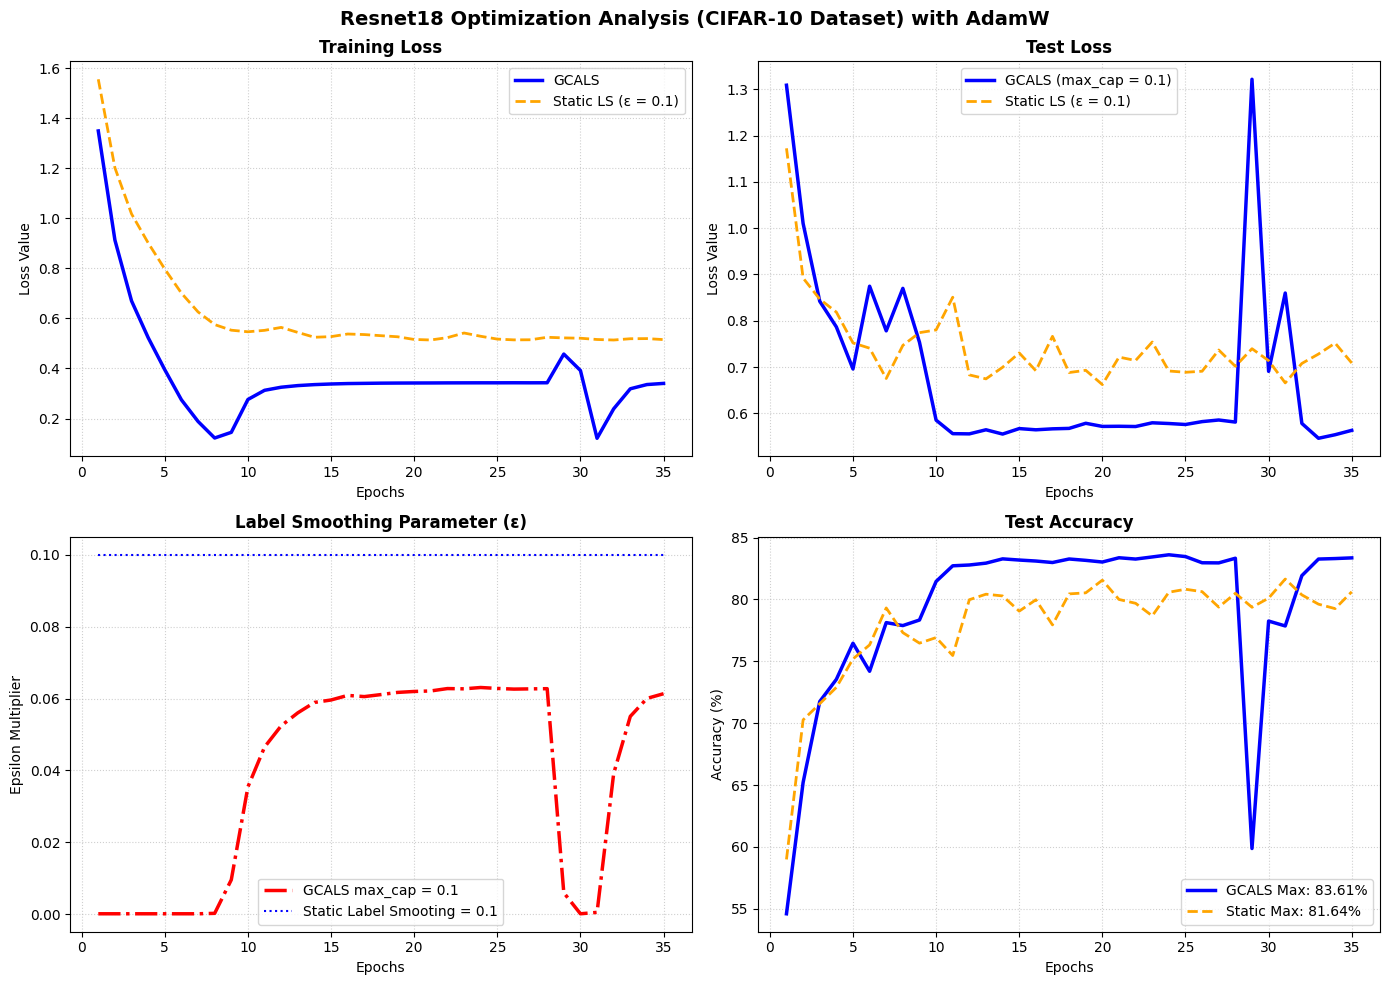

In [14]:

epochs_range = range(1, num_epochs + 1)
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 10))

# Train Loss
ax1.plot(epochs_range, gcals_train, color='blue', linewidth=2.5, label='GCALS')
ax1.plot(epochs_range, static_train, color='orange', linestyle='--', linewidth=2.0, label=f'Static LS (ε = {eps})')
# ax1.plot(epochs_range, none_train, color='green', linestyle='--', linewidth=2.0, label=f'No LS (ε = 0.0)')
ax1.set_title('Training Loss', fontweight='bold')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss Value')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# Test Loss
ax2.plot(epochs_range, gcals_test, color='blue', linewidth=2.5, label=f'GCALS (max_cap = {eps})')
ax2.plot(epochs_range, static_test, color='orange', linestyle='--', linewidth=2.0, label=f'Static LS (ε = {eps})')
# ax2.plot(epochs_range, none_test, color='green', linestyle='--', linewidth=2.0, label=f'No LS (ε = 0.0)')
ax2.set_title('Test Loss', fontweight='bold')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Loss Value')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

# Epsilon Trajectory
ax3.plot(epochs_range, gcals_epsilons, color='red', linestyle='-.', linewidth=2.5, label=f'GCALS max_cap = {eps} ')
ax3.plot(epochs_range, static_epsilons, color='blue', linestyle=':', linewidth=1.5, label=f'Static Label Smooting = {eps}')
# ax3.plot(epochs_range, none_epsilons, color='green', linestyle=':', linewidth=1.5, label=f'No Label Smooting = 0.0')
ax3.set_title('Label Smoothing Parameter (ε)', fontweight='bold')
ax3.set_xlabel('Epochs')
ax3.set_ylabel('Epsilon Multiplier')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend()

# Test Accuracy Performance
ax4.plot(epochs_range, gcals_acc, color='blue', linewidth=2.5, label=f"GCALS Max: {max(gcals_acc):.2f}%")
ax4.plot(epochs_range, static_acc, color='orange', linestyle='--', linewidth=2.0, label=f"Static Max: {max(static_acc):.2f}%")
# ax4.plot(epochs_range, none_acc, color='green', linestyle='--', linewidth=2.0, label=f"No LS Max: {max(none_acc):.2f}%")
ax4.set_title('Test Accuracy', fontweight='bold')
ax4.set_xlabel('Epochs')
ax4.set_ylabel('Accuracy (%)')
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend(loc='lower right')

plt.suptitle('Resnet18 Optimization Analysis (CIFAR-10 Dataset) with AdamW', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.savefig('gcals_cifar10_adamw_benchmark.png', dpi=300)
plt.show()


The sudden collapse in accuracy and epsilon, I suspect, is due to AdamW's behavior as we can see a sudden spike in training loss at the corresponding epoch this also led a sudden spike in test loss.